In [146]:
import pandas as pd
import numpy as np
import pandas_ta as ta
import matplotlib.pyplot as plt

In [147]:
df = pd.read_csv("./NQFuturesData/combined.csv")
df = df.drop(columns=['Change', '%Chg', 'Volume'])
df = df.set_index('Time')

# df = df[1_300_000:]

In [148]:
# remove duplicates 
df = df.groupby(df.index).min()
print(df.index.is_unique)  # Should print True


True


In [149]:
df.index = pd.to_datetime(df.index)
df = df.resample('3min', label='right', closed='right').agg({
    'Open': 'first',
    'High': 'max',
    'Low': 'min',
    'Close': 'last',
}).dropna().shift(1)
df.size

2036440

In [150]:
# Constants
EMSD_SHORT_WEIGHT = 0.7
EMSD_LONG_WEIGHT = 0.3
EMSD_SHORT_LENGTH = 64 * 2
EMSD_LONG_LENGTH = 256 * 2

In [151]:
close = df['Close']


# N and 4N pairs
ema_8 = ta.ema(close, 8)
ema_32 = ta.ema(close, 32)

ema_16 = ta.ema(close, 16)
ema_64 = ta.ema(close, 64)

ema_256 = ta.ema(close, 256)
# print(close.ewm(span=EMSD_SHORT_LENGTH).std())
# emsd = close.ewm(span=EMSD_SHORT_LENGTH).std() * EMSD_SHORT_WEIGHT + close.ewm(span=EMSD_LONG_LENGTH).std() * EMSD_LONG_WEIGHT

# drop all nan values and sync them up
sync_df = pd.DataFrame({
    'ema8': ema_8,
    'ema16': ema_16,
    'ema32': ema_32,
    'ema64': ema_64,
    'ema256': ema_256,
}).dropna()

ema_8 = sync_df['ema8']
ema_16 = sync_df['ema16']
ema_32 = sync_df['ema32']
ema_64 = sync_df['ema64']
ema_256 = sync_df['ema256'] 


# calculate forecasts
signal_8_32 = (ema_8 - ema_32)
signal_16_64 = (ema_16 - ema_64)
signal_64_256 = (ema_64 - ema_256)

volitility_8_32 = signal_8_32.ewm(span=EMSD_SHORT_LENGTH).std() * EMSD_SHORT_WEIGHT + signal_8_32.ewm(span=EMSD_LONG_LENGTH).std() * EMSD_LONG_WEIGHT
volitility_16_64 = signal_16_64.ewm(span=EMSD_SHORT_LENGTH).std() * EMSD_SHORT_WEIGHT + signal_16_64.ewm(span=EMSD_LONG_LENGTH).std() * EMSD_LONG_WEIGHT
volitility_64_256 = signal_64_256.ewm(span=EMSD_SHORT_LENGTH).std() * EMSD_SHORT_WEIGHT + signal_64_256.ewm(span=EMSD_LONG_LENGTH).std() * EMSD_LONG_WEIGHT

raw_forecast_8_32 = signal_8_32 / volitility_8_32
raw_forecast_16_64 = signal_16_64 / volitility_16_64
raw_forecast_64_256 = signal_64_256 / volitility_64_256



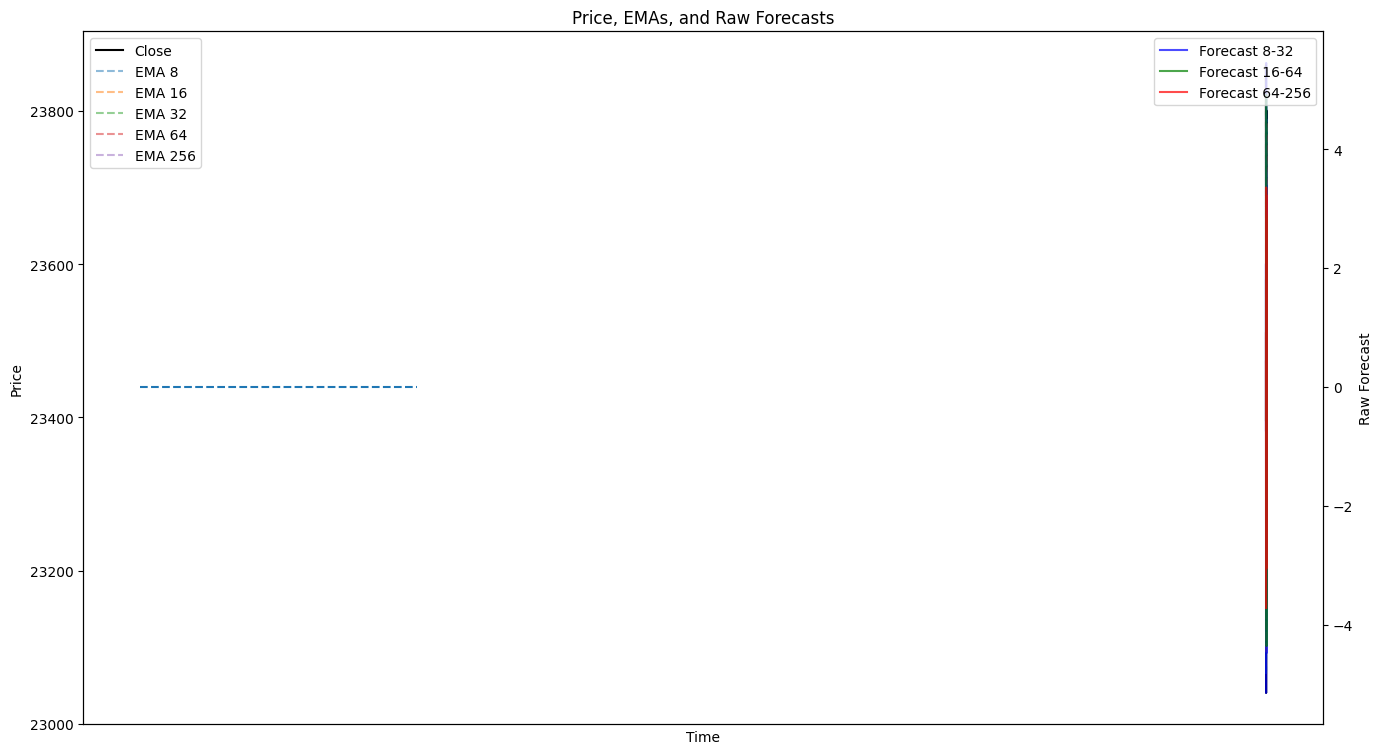

In [152]:
window = -5000  # your window for plotting

fig, ax1 = plt.subplots(figsize=(16, 9))

# --- Price and EMAs ---
ax1.plot(df['Close'][window:], label='Close', color='black', linewidth=1.5)
ax1.plot(ema_8[window:], label='EMA 8', linestyle='--', alpha=0.5)
ax1.plot(ema_16[window:], label='EMA 16', linestyle='--', alpha=0.5)
ax1.plot(ema_32[window:], label='EMA 32', linestyle='--', alpha=0.5)
ax1.plot(ema_64[window:], label='EMA 64', linestyle='--', alpha=0.5)
ax1.plot(ema_256[window:], label='EMA 256', linestyle='--', alpha=0.5)

ax1.set_xlabel("Time")
ax1.set_ylabel("Price")
ax1.set_xticks([])  # hide x-axis numbers
ax1.legend(loc='upper left')
ax1.set_title("Price, EMAs, and Raw Forecasts")

# --- Forecasts on secondary axis ---
ax2 = ax1.twinx()  # create secondary y-axis
ax2.plot(raw_forecast_8_32[window:], label='Forecast 8-32', color='blue', alpha=0.7)
ax2.plot(raw_forecast_16_64[window:], label='Forecast 16-64', color='green', alpha=0.7)
ax2.plot(raw_forecast_64_256[window:], label='Forecast 64-256', color='red', alpha=0.7)
ax2.hlines([0],xmin=0, xmax=-window, linestyles='--')
# ax2.plot(position_size[window:], label='Position Size', color='yellow')

ax2.set_ylabel("Raw Forecast")
ax2.legend(loc='upper right')

plt.show()


In [153]:
df = pd.DataFrame({
    '8_32': raw_forecast_8_32,
    '16_64': raw_forecast_16_64,
    '64_256': raw_forecast_64_256,
    '8_ema': ema_8,
    '16_ema': ema_16,
    '32_ema': ema_32,
    '64_ema': ema_64,
    '256_ema': ema_256,
    'close': close
})


In [154]:
# import plotly.graph_objects as go
# from plotly.subplots import make_subplots
# import numpy as np

# # Make sure df has these columns filled by lookup or mapping
# # e.g., df['8_32_8ema'], df['8_32_16ema'], etc.

# window_size = 3000
# start = len(df) - window_size

# # Helper to build hover text
# def make_hover_text(df_slice, prefix):
#     texts = []
#     for _, row in df_slice.iterrows():
#         text = (
#             f"<b>{prefix}</b><br>"
#             f"Forecast: {row[prefix]:.3f}<br>"
#             f"P(Close<8EMA): {row.get(f'{prefix}_8ema', np.nan):.2f}<br>"
#             f"P(Close<16EMA): {row.get(f'{prefix}_16ema', np.nan):.2f}<br>"
#             f"P(Close<32EMA): {row.get(f'{prefix}_32ema', np.nan):.2f}<br>"
#             f"P(Close<64EMA): {row.get(f'{prefix}_64ema', np.nan):.2f}<br>"
#             f"P(Close<256EMA): {row.get(f'{prefix}_256ema', np.nan):.2f}"
#         )
#         texts.append(text)
#     return texts


# # Build figure
# fig = make_subplots(specs=[[{"secondary_y": True}]])

# # --- PRICE & EMAs ---
# fig.add_trace(go.Scatter(
#     x=df.index[start:], y=df['close'][start:],
#     mode='lines', name='Close', line=dict(color='black', width=2)
# ), secondary_y=False)

# for ema, color in zip(
#     ['8_ema', '16_ema', '32_ema', '64_ema', '256_ema'],
#     ['orange', 'purple', 'teal', 'gray', 'brown']
# ):
#     fig.add_trace(go.Scatter(
#         x=df.index[start:], y=df[ema][start:],
#         mode='lines', name=ema,
#         line=dict(dash='dot', color=color, width=1)
#     ), secondary_y=False)

# # --- FORECASTS (with hover info) ---
# colors = {'8_32': 'blue', '16_64': 'green', '64_256': 'red'}

# for prefix, color in colors.items():
#     hover_text = make_hover_text(df.iloc[start:], prefix)
#     fig.add_trace(go.Scatter(
#         x=df.index[start:], y=df[prefix][start:],
#         mode='lines', name=f'Forecast {prefix}',
#         line=dict(color=color, width=1.5),
#         hovertemplate='%{text}<extra></extra>',
#         text=hover_text
#     ), secondary_y=True)

# # --- Formatting ---
# fig.add_hline(y=0, line=dict(color='gray', dash='dot'), secondary_y=True)

# fig.update_layout(
#     title='Price, EMAs, Forecasts, and Probabilities',
#     hovermode='x unified',
#     xaxis=dict(rangeslider=dict(visible=True)),
#     # template='plotly_dark',
#     height=750,
#     legend=dict(yanchor="top", y=1.05, xanchor="left", x=0.01),
#     hoverlabel=dict(
#         bgcolor='rgba(0,0,0,0.5)',
#         font=dict(size=12, color='white'),
#         align='right',
#         bordercolor='rgba(255,255,255,0.2)'
#     )

# )

# fig.update_yaxes(title_text="Price", secondary_y=False)
# fig.update_yaxes(title_text="Forecast Value", secondary_y=True)

# fig.show()


In [155]:
df['return'] = df['close'].pct_change()
np_returns = df['return'].to_numpy(dtype=np.float32)

def calculate_returns(signal):
    
    shifted_signal = signal.shift(1)
    strategy_return = shifted_signal * df['return']
    flips = (shifted_signal != shifted_signal.shift(1).fillna(0)).sum()
    percetage_return = (1 + strategy_return).prod() - 1
    # percetage_return -= flips * 0.001
    return percetage_return * 100


cumulative_market = ((1 + df['return']).prod() - 1) * 100
print(f'Buy & Hold Returns: {round(cumulative_market, 2)}%')



Buy & Hold Returns: 1081.59%


In [156]:
# from itertools import product
# import time

# # define parameter search space
# start = -1
# end = 0
# step = 0.1
# weights = np.arange(start, end + step, step)  # between -1 and 1 for each forecast
# results = []

# np_8_32 = df['8_32'].to_numpy(dtype=np.float32)
# np_16_64 = df['16_64'].to_numpy(dtype=np.float32)
# np_64_256 = df['64_256'].to_numpy(dtype=np.float32)
# for w1, w2, w3 in product(weights, repeat=3):

#     combined_forecast = np_8_32 * w1 + np_16_64 * w2 + np_64_256 * w3
#     signal = np.zeros_like(combined_forecast, dtype=np.int8)
#     signal[combined_forecast > 1] = 1
#     signal[combined_forecast < -1] = -1
#     signal = pd.Series(signal, index=df.index)
#     strat_return = calculate_returns(signal)
    
#     results.append((w1, w2, w3, strat_return))

# # convert results to DataFrame
# res_df = pd.DataFrame(results, columns=['w1', 'w2', 'w3', 'return'])

# # find best weights
# best = res_df.loc[res_df['return'].idxmax()]
# print(f"Best Weights: w1={best.w1}, w2={best.w2}, w3={best.w3}, Return={best['return']:.2f}%")

# # plot a 2D heatmap slice of w1/w2 for fixed w3 = 0
# slice_df = res_df[np.isclose(res_df['w3'], 0)]
# pivot = slice_df.pivot(index='w1', columns='w2', values='return')

# plt.figure(figsize=(8, 6))
# plt.title("Strategy Return Heatmap (w3 = 0 slice)")
# plt.imshow(pivot.values, origin='lower', extent=[start, end, start, end], aspect='auto')
# plt.colorbar(label='Cumulative Return (%)')
# plt.xlabel('Weight 2 (16_64)')
# plt.ylabel('Weight 1 (8_32)')
# plt.show()

In [157]:
import optuna

weight_start = -30
weight_end = 30
no_trade_range = 20
np_8_32 = df['8_32'].to_numpy(dtype=np.float32)
np_16_64 = df['16_64'].to_numpy(dtype=np.float32)
np_64_256 = df['64_256'].to_numpy(dtype=np.float32)

clip_min = -20
clip_max = 20
np_8_32 = np.clip(np_8_32, clip_min, clip_max)
np_16_64 = np.clip(np_16_64, clip_min, clip_max)
np_64_256 = np.clip(np_64_256, clip_min, clip_max)

trials = 2000

def generate_signal(w1, w2, w3, w4):
    combined_forecast = np_8_32 * w1 + np_16_64 * w2 + np_64_256 * w3
    combined_forecast = combined_forecast / clip_max
    signal = np.zeros_like(combined_forecast, dtype=np.float32)

    # long_pos = combined_forecast > w4
    # short_pos = combined_forecast < -w4
    signal[combined_forecast > w4] = 1
    signal[combined_forecast < -w4] = -1

    # signal[long_pos] = combined_forecast[long_pos]
    # signal[short_pos] = combined_forecast[short_pos]
    # # signal[d] = combined_forecast
    # signal[combined_forecast < -w4] = combined_forecast
    return pd.Series(signal, index=df.index)

def objective(trial):
    w1 = trial.suggest_float('w1', weight_start, weight_end)
    w2 = trial.suggest_float('w2', weight_start, weight_end)
    w3 = trial.suggest_float('w3', weight_start, weight_end)
    w4 = trial.suggest_float('w4', 0, no_trade_range)

    return -calculate_returns(generate_signal(w1, w2, w3, w4))

study = optuna.create_study()
study.optimize(objective, n_trials=trials)
print(study.best_params)
print(-study.best_value)


[I 2025-11-17 23:08:32,073] A new study created in memory with name: no-name-aaaf56a3-2590-4164-bedf-656b3ccc12df
[I 2025-11-17 23:08:32,087] Trial 0 finished with value: -0.333724802411961 and parameters: {'w1': -14.407849897946246, 'w2': 10.050681733727409, 'w3': -8.227654458518757, 'w4': 4.603609900497878}. Best is trial 0 with value: -0.333724802411961.
[I 2025-11-17 23:08:32,095] Trial 1 finished with value: -2.658778838115783 and parameters: {'w1': -17.86461583017897, 'w2': -28.633528147475438, 'w3': 27.99219402351546, 'w4': 11.619271740240622}. Best is trial 1 with value: -2.658778838115783.
[I 2025-11-17 23:08:32,104] Trial 2 finished with value: 93.01722021318804 and parameters: {'w1': 19.739620009510645, 'w2': 19.57390726350029, 'w3': 14.170246652724295, 'w4': 1.4585097562993554}. Best is trial 1 with value: -2.658778838115783.
[I 2025-11-17 23:08:32,112] Trial 3 finished with value: -6.234405235054119 and parameters: {'w1': -17.778726481191757, 'w2': -26.54115241092888, 'w3'

{'w1': -27.3635243901209, 'w2': 7.783187673887863, 'w3': -2.6871533056961905, 'w4': 0.005937296254660194}
2000.578605043011


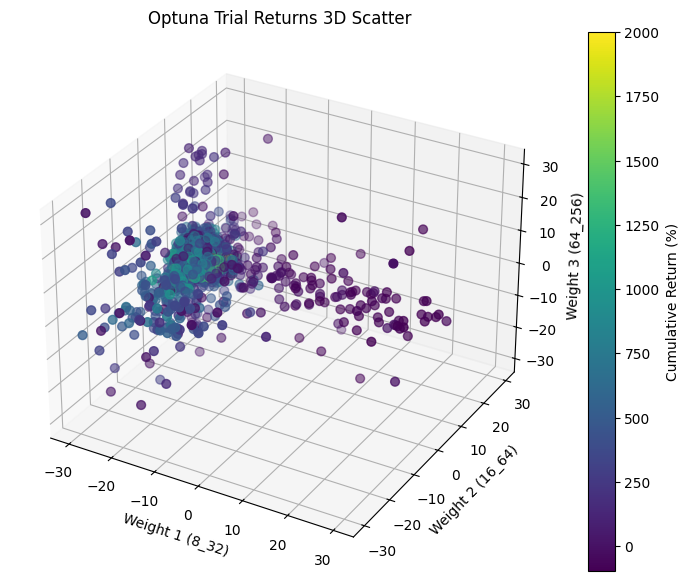

In [158]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D plotting
import numpy as np
import pandas as pd
# Extract all trials from the study
trials_df = study.trials_dataframe()

# Columns in trials_df: 'number', 'value', 'params_w1', 'params_w2', 'params_w3', ...
# We'll use params_w1, params_w2, params_w3, and value (negative return)
w1_vals = trials_df['params_w1'].to_numpy()
w2_vals = trials_df['params_w2'].to_numpy()
w3_vals = trials_df['params_w3'].to_numpy()
returns = -trials_df['value'].to_numpy()  # convert back to positive return

# 3D scatter plot of the trials
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(w1_vals, w2_vals, w3_vals, c=returns, cmap='viridis', s=40)
ax.set_xlabel('Weight 1 (8_32)')
ax.set_ylabel('Weight 2 (16_64)')
ax.set_zlabel('Weight 3 (64_256)')
plt.title('Optuna Trial Returns 3D Scatter')
plt.colorbar(sc, label='Cumulative Return (%)')
plt.show()




Weight 1 (8_32): u: -25.39465115467125, median: -26.037952177127764
Weight 2 (16_64): u: 6.112208877454817, median: 7.604405355146646
Weight 3 (64_256): u: -3.1684531539096037, median: -3.1278640307099845
Weight 4 (no trade): u: 0.26214389912036923, median: 0.3492485620767734


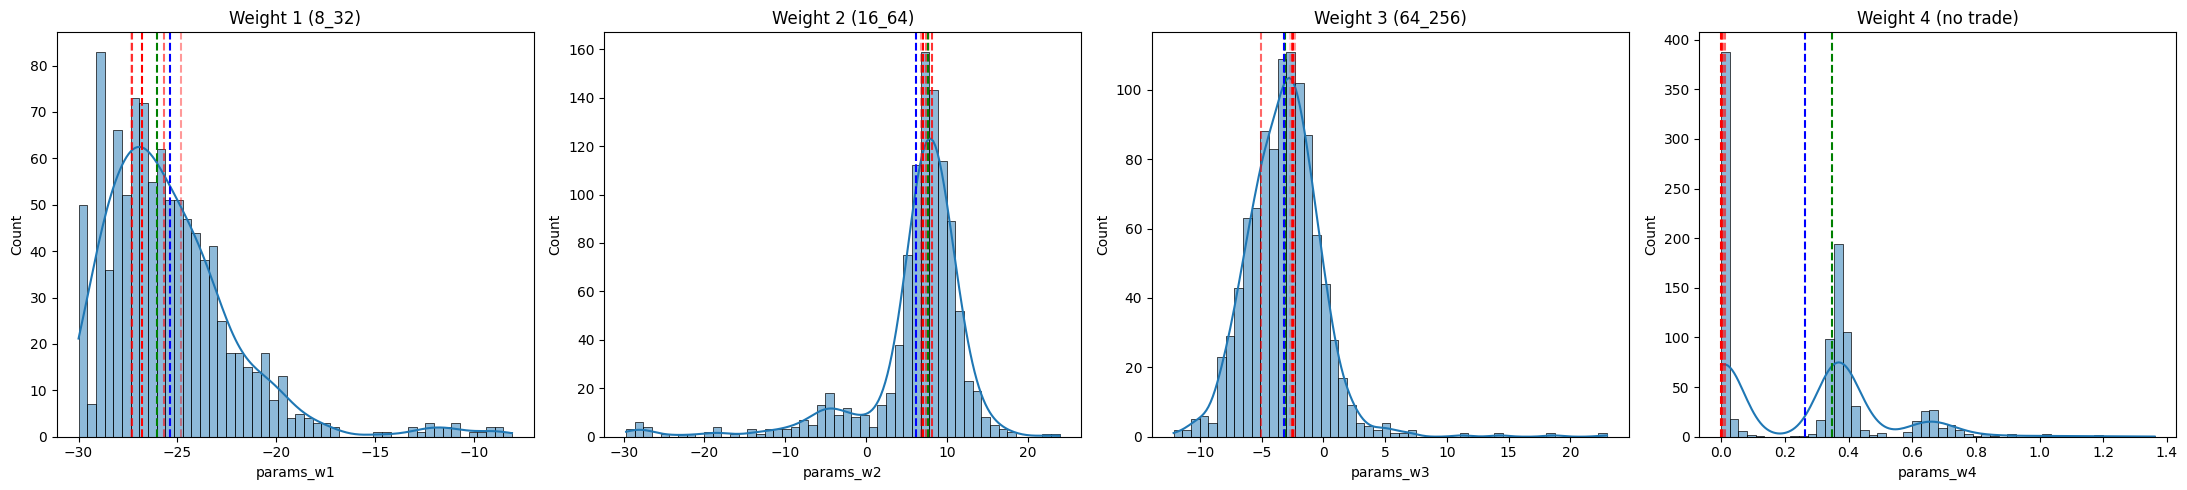

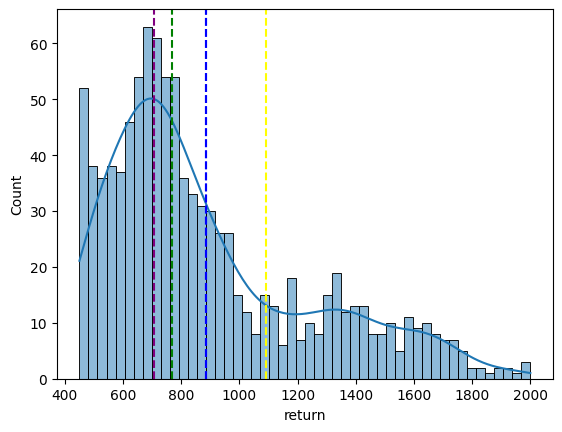

In [159]:
import seaborn as sns
import matplotlib.pyplot as plt

top_n = trials // 2
best_trails = 5
trials_df = study.trials_dataframe()

# Get top N trials by performance (highest return)
top_trials = trials_df.nsmallest(top_n, 'value').copy()  # value is negative return
top_trials['return'] = -top_trials['value']  # convert back to positive return

# Get top 3 trials overall
best3 = top_trials.nsmallest(best_trails, 'value').copy()
best3['return'] = -best3['value']

plt.figure(figsize=(22,5))

weights = ['params_w1', 'params_w2', 'params_w3', 'params_w4']
titles = ['Weight 1 (8_32)', 'Weight 2 (16_64)', 'Weight 3 (64_256)', 'Weight 4 (no trade)']

mean_weights = []
median_weights = []

for i, col in enumerate(weights):
    plt.subplot(1,4,i+1)
    sns.histplot(top_trials[col], bins=50, kde=True)
    plt.title(titles[i])
    
    # Overlay top 3 lines
    count = 1
    for j, row in best3.iterrows():
        alpha = count/best_trails  # fade: best=most opaque
        count += 1
        plt.axvline(row[col], color='red', alpha=alpha, linestyle='--')

    plt.axvline(top_trials[col].median(), color='green', alpha=alpha, linestyle='--')
    plt.axvline(top_trials[col].mean(), color='blue', alpha=alpha, linestyle='--')
    print(f'{titles[i]}: u: {top_trials[col].mean()}, median: {top_trials[col].median()}')
    
    mean_weights.append(top_trials[col].mean())
    median_weights.append(top_trials[col].median())
    

plt.tight_layout()
plt.show()

sns.histplot(top_trials['return'], bins=50, kde=True)

# describe the mean and median
plt.axvline(top_trials['return'].median(), color='green', alpha=alpha, linestyle='--', label=f'{top_trials['return'].median()}')
plt.axvline(top_trials['return'].mean(), color='blue', alpha=alpha, linestyle='--',  label=f'{top_trials['return'].mean()}')

# median and mean weight equity returns
median_return = calculate_returns(generate_signal(*median_weights))
mean_return = calculate_returns(generate_signal(*mean_weights))
plt.axvline(top_trials['return'].mean(), color='blue', alpha=alpha, linestyle='--',  label=f'{top_trials['return'].mean()}')
plt.axvline(median_return, color='purple', alpha=alpha, linestyle='--',  label=f'{top_trials['return'].mean()}')
plt.axvline(mean_return, color='yellow', alpha=alpha, linestyle='--',  label=f'{top_trials['return'].mean()}')
plt.show()


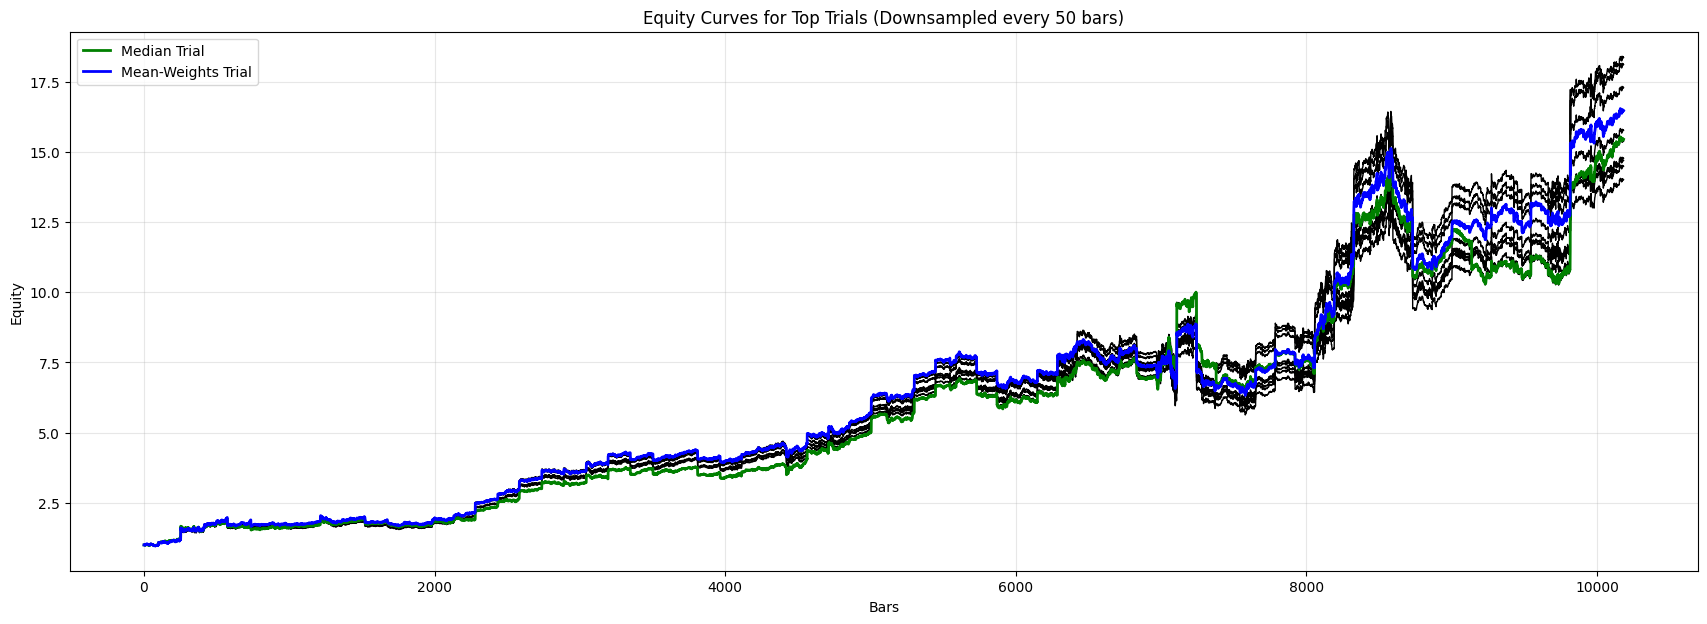

In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# Helper: compute equity curve
# ----------------------------
def equity_curve_from_weights(w1, w2, w3):
    signal_raw = np_8_32 * w1 + np_16_64 * w2 + np_64_256 * w3
    signal = np.zeros_like(signal_raw, dtype=np.int8)
    signal[signal_raw > 1] = 1
    signal[signal_raw < -1] = -1
    strat_return = pd.Series(signal, index=df.index).shift(1) * df['return']
    return (1 + strat_return).cumprod()

# ----------------------------
# Get top trials + weights
# ----------------------------
top_n = 10
trials_df = study.trials_dataframe()
top_df = trials_df.nsmallest(top_n, "value").copy()
top_df["return"] = -top_df["value"]
weights = top_df[["params_w1", "params_w2", "params_w3"]].values

# ----------------------------
# Compute equity curves
# ----------------------------
equity_curves = [equity_curve_from_weights(w1, w2, w3) for w1, w2, w3 in weights]
equity_df = pd.concat(equity_curves, axis=1)
equity_df.columns = range(top_n)

# ----------------------------
# Median + mean-weight curves
# ----------------------------
final_values = equity_df.iloc[-1]
median_idx = final_values.median()
median_trial = final_values.sub(median_idx).abs().idxmin()

mean_w = top_df[["params_w1", "params_w2", "params_w3"]].mean().values
mean_eq = equity_curve_from_weights(*mean_w)

# ----------------------------
# FAST DOWNSAMPLING (auto)
# ----------------------------
target_points = 10000
down = max(1, len(equity_df) // target_points)

equity_df_ds = equity_df.iloc[::down]
mean_eq_ds = mean_eq.iloc[::down]

# ----------------------------
# PLOT
# ----------------------------
plt.figure(figsize=(21, 7))

for col in equity_df_ds.columns:
    plt.plot(equity_df_ds[col].values, color='black', linewidth=1)

plt.plot(equity_df_ds[median_trial].values, color='green', linewidth=2, label='Median Trial')
plt.plot(mean_eq_ds.values, color='blue', linewidth=2, label='Mean-Weights Trial')


plt.title(f"Equity Curves for Top Trials (Downsampled every {down} bars)")
plt.xlabel("Bars")
plt.ylabel("Equity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


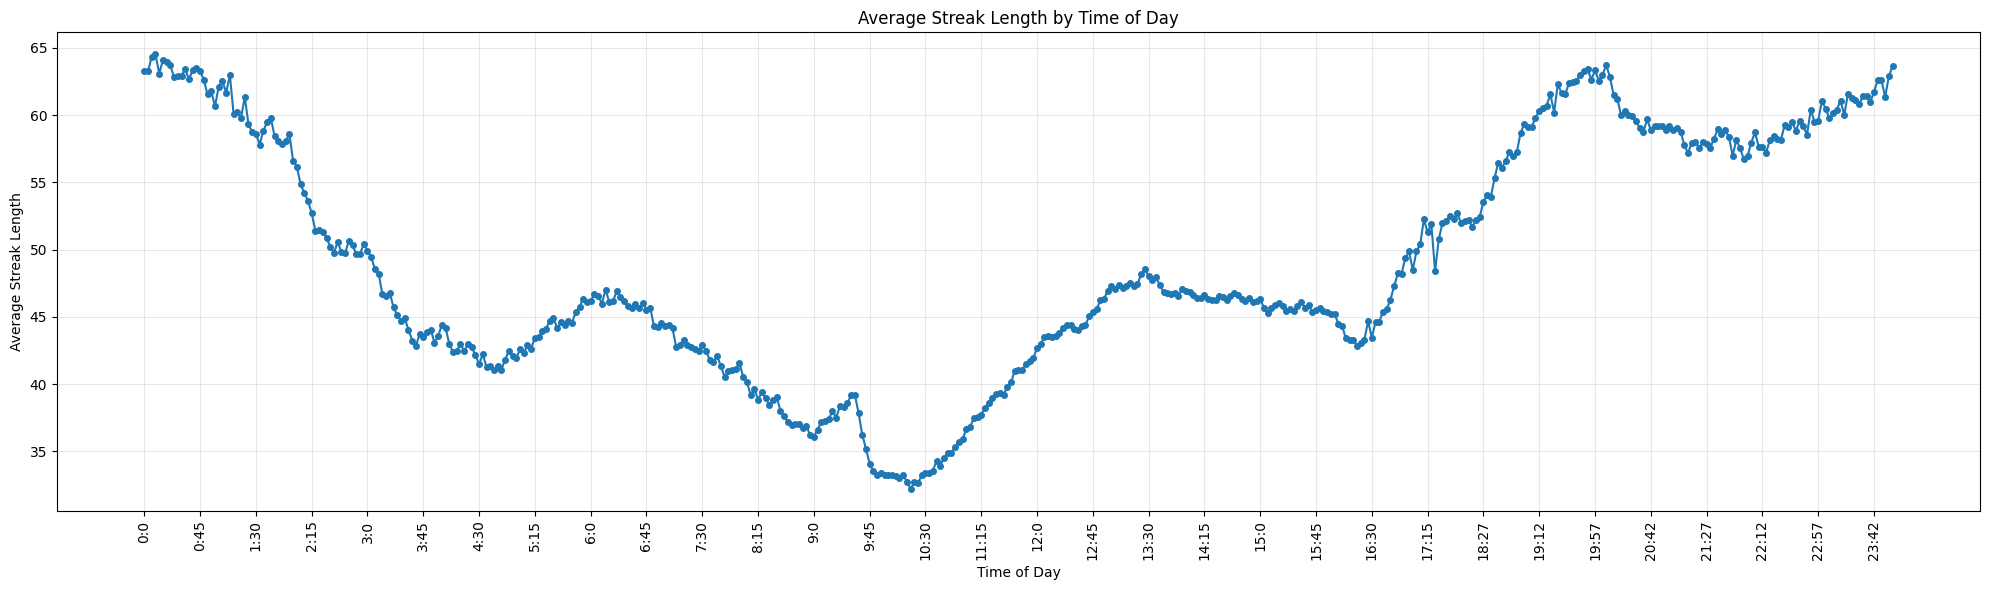

In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ----------------------------
# Compute streaks (vectorized)
# ----------------------------
w1 = -18.15451124782517
w2 = -8.637803526827886
w3 = -3.527284884065461
w4 = 0.02169602541391937 

df['signal'] = generate_signal(w1, w2, w3, w4)

# points where streak resets
reset = df['signal'].ne(df['signal'].shift())

# cumulative count of resets
group = reset.cumsum()

# within each group, count from zero
df['streak'] = df.groupby(group).cumcount()

df.index = pd.to_datetime(df.index)
df.index = df.index.tz_localize('US/Central').tz_convert('US/Eastern')
hour_minute_counts = df.groupby([df.index.hour, df.index.minute])
hour_minute_mean_streaks = hour_minute_counts['streak'].mean()


# Convert MultiIndex (hour, minute) to datetime.time for plotting
times = [f'{h}:{m}' for h, m in hour_minute_mean_streaks.index]
# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(20, 6))
plt.plot(times, hour_minute_mean_streaks, marker='o', linestyle='-', markersize=4)

plt.xlabel("Time of Day")
plt.ylabel("Average Streak Length")
plt.title("Average Streak Length by Time of Day")
plt.xticks(times[::15], rotation=90)



plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()